# KPP–Fisher with position-dependent coefficients, in 2-D

This example runs the position-dependent coefficients of
[`kpp_fisher_position_dependent_1d`](kpp_fisher_position_dependent_1d.ipynb) on a $12\times12$ grid
with a rectangular inclusion. Nothing in the assembly is dimension-specific.

:::{seealso}
- [`kpp_fisher_position_dependent_1d`](kpp_fisher_position_dependent_1d.ipynb) defines **zone**,
  **key** and the abbreviation **CL**, and checks the assembly against a dense one. Read that page
  first.
:::

That page sets up the zone-aware assembly: `fisher` writes the coefficients as one `sp.Piecewise`,
and `classify_by_zone` tags each site with its zone. `shape` and `box` simply grow a second entry
here, so this notebook reproduces both unchanged.

## Assembly

Copied from [`kpp_fisher_position_dependent_1d`](kpp_fisher_position_dependent_1d.ipynb) so this
notebook runs on its own. The reasoning, the figures and the correctness checks stay there.


In [1]:

import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.sparse import csc_matrix, csr_matrix
from scipy.sparse.linalg import expm_multiply
from scipy.integrate import solve_ivp

from lin_ode.basis import CarlemanBasis, CarlemanState
from lin_ode import OperatorMatrix
from lin_ode.operators import Koopman
from lin_ode import OrdinaryDifferentialSystem
from collections.abc import Callable, Hashable, Iterator

from lin_ode.vector import Vector

# one set of coefficients per zone: 1 inside the box, 0 outside
D_0, D_1, Q_0, Q_1, R_0, R_1, h = sp.symbols("D_0 D_1 Q_0 Q_1 R_0 R_1 h", real=True)
u = sp.IndexedBase("u")  # field symbol; the basis supplies only the sites and powers


def coord(label):  # site label -> integer coordinate tuple (wraps the bare 1-D scalar)
    return tuple(int(v) for v in label) if isinstance(label, (sp.Tuple, tuple)) else (int(label),)


def as_monomial(*factors):  # CarlemanState((site, power), ...) -> u[site]**power * ...
    return sp.Mul(*[u[coord(site)] ** power for site, power in factors])

def in_box(site, box):  # is this coordinate tuple inside the closed box ((lo, hi), ...)?
    return all(lo <= axis_val <= hi for axis_val, (lo, hi) in zip(site, box))

StateLabel = tuple[tuple[int, int], ...]  # a state, as its (site, power) factors
CanonicalFactors = tuple[tuple[tuple[int, ...], int], ...]  # ((coordinates, power), ...), sorted
ZonedFactors = tuple[tuple[tuple[int, ...], int, Hashable], ...]  # ... plus the site's zone
ZonedKey = tuple[ZonedFactors, ZonedFactors]  # (bra, ket), what classify_by_zone returns
Zone = Callable[[tuple[int, ...]], Hashable]  # a coordinate tuple to its zone label



In [2]:
def fisher(shape: tuple[int, ...], box: tuple[tuple[int, int], ...]) -> OrdinaryDifferentialSystem:
    """Fisher-KPP on a grid of `shape`, with (D, Q, R) switching to zone 1 inside `box`."""
    idx = tuple(sp.Idx(name, (0, size - 1)) for name, size in zip("ijk", shape))
    site = u[idx]

    def arm(axis: int, step: int) -> sp.Expr:
        """One stencil neighbour: 0 where it leaves the grid, which is the Dirichlet end.

        Index arithmetic wraps by default, so an open axis has to say so.
        """
        shifted = idx[axis] + step
        neighbour = u[idx[:axis] + (shifted,) + idx[axis + 1:]]
        on_the_grid = shifted >= 0 if step == -1 else shifted <= shape[axis] - 1
        return sp.Piecewise((neighbour, on_the_grid), (0, sp.true))

    laplacian = (
        sum(arm(a, step) for a in range(len(idx)) for step in (-1, 1)) - 2 * len(idx) * site
    ) / h**2
    inside = sp.And(*[rel for a, (lo, hi) in enumerate(box) for rel in (idx[a] >= lo, idx[a] <= hi)])
    rhs = sp.piecewise_fold(sp.Piecewise(
        (D_1 * laplacian + Q_1 * site + R_1 * site**2, inside),
        (D_0 * laplacian + Q_0 * site + R_0 * site**2, True),
    ))
    return OrdinaryDifferentialSystem.from_sympy(rhs, u, idx)


fisher((6,), ((2, 3),)).equation.expr

Piecewise((D_1*(u[Mod(i + 1, 6)] + u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 1) & (i >= 2) & (i <= 3) & (i <= 4)), (D_1*(u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 1) & (i >= 2) & (i <= 3)), (D_1*(u[Mod(i + 1, 6)] - 2*u[i])/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 2) & (i <= 3) & (i <= 4)), (-2*D_1*u[i]/h**2 + Q_1*u[i] + R_1*u[i]**2, (i >= 2) & (i <= 3)), (D_0*(u[Mod(i + 1, 6)] + u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, (i >= 1) & (i <= 4)), (D_0*(u[Mod(i + 5, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, i >= 1), (D_0*(u[Mod(i + 1, 6)] - 2*u[i])/h**2 + Q_0*u[i] + R_0*u[i]**2, i <= 4), (-2*D_0*u[i]/h**2 + Q_0*u[i] + R_0*u[i]**2, True))

In [3]:
def as_factors(state: CarlemanState) -> StateLabel:
    """A CarlemanState as canonical (coordinate-tuple, power) factors."""
    return tuple((coord(label), int(power)) for label, power in state.args)


def iter_neighbours(site: tuple[int, ...], shape: tuple[int, ...]) -> Iterator[tuple[int, ...]]:
    """The in-grid ±1 neighbours of `site`, one per axis and direction.

    Out-of-grid neighbours are simply not yielded, which is the Dirichlet end.
    """
    for axis, size in enumerate(shape):
        shifted = list(site)
        for step in (-1, 1):
            shifted[axis] = site[axis] + step
            if 0 <= shifted[axis] < size:
                yield tuple(shifted)


def find_reachable_bras(ket: StateLabel, shape: tuple[int, ...], degree: int) -> set[StateLabel]:
    """Bras a ket couples to: itself, one diffusion hop, and the reaction term."""
    state = CarlemanState(*ket)
    bras = {as_factors(state)}
    total_degree = sum(power for _, power in ket)

    for label, power in ket:
        for site in iter_neighbours(coord(label), shape):          # diffusion
            hopped = state.update_dim(label, power - 1)
            bras.add(as_factors(hopped.update_dim(site, state.get_n(site) + 1)))
        if total_degree < degree:                             # reaction
            bras.add(as_factors(state.update_dim(label, power + 1)))
    return bras

In [4]:
def canonicalise_positions(sites: list[tuple[int, ...]], radius: int) -> list[dict[int, int]]:
    """Per axis, a map from each occurring coordinate to its canonical position.

    Gaps wider than the stencil radius are capped at `radius + 1`, because sites
    farther apart than the radius do not interact.
    """
    maps = []
    for axis in range(len(sites[0])):
        present = sorted({site[axis] for site in sites})
        position, axis_map = 0, {}
        for rank, value in enumerate(present):
            if rank:
                position += min(value - present[rank - 1], radius + 1)
            axis_map[value] = position
        maps.append(axis_map)
    return maps


def classify_by_zone(bra: StateLabel, ket: StateLabel, zone: Zone, radius: int = 1) -> ZonedKey:
    """`classify_by_shift`, with each site also tagged by its coefficient zone."""
    sites = [coord(label) for label, _ in bra + ket]
    if not sites:
        return (), ()
    relabel = canonicalise_positions(sites, radius)

    def canonical(factors: StateLabel) -> ZonedFactors:
        return tuple(sorted(
            (tuple(m[c] for m, c in zip(relabel, coord(label))), power, zone(coord(label)))
            for label, power in factors
        ))

    return canonical(bra), canonical(ket)

In [5]:
def build(
    matrix: OperatorMatrix, basis: CarlemanBasis, zone
) -> tuple[dict[tuple[int, int], sp.Expr], dict[tuple, sp.Expr]]:
    """Assemble the sparse generator {(bra, ket): value}, calling M[bra,ket] once per classify_by_zone."""
    shape, degree = coord(basis.n_vars), basis.degree  # the basis already carries the grid and truncation
    entries, value = {}, {}
    for ket_flat in range(len(basis)):
        ket = basis.structured_idx_of_flat_index(ket_flat)
        for bra in find_reachable_bras(ket, shape, degree):
            key = classify_by_zone(bra, ket, zone)
            if key not in value:
                value[key] = matrix[bra, ket]  # <-- M[bra, ket], once per shape-and-zone pattern
            if value[key] != 0:
                entries[(basis.flat_index_of_structured_index(bra), ket_flat)] = value[key]
    return entries, value


def carleman_matrix(entries: dict[tuple[int, int], sp.Expr], dim: int) -> csc_matrix:
    """Carleman matrix A = M^T from the sparse generator entries {(bra, ket): value}."""
    rows, cols = zip(*entries)
    data = [float(val) for val in entries.values()]  # real coefficients, real field: no complex anywhere
    return csr_matrix((data, (rows, cols)), shape=(dim, dim)).T.tocsc()


def numeric(shape, box, values) -> OrdinaryDifferentialSystem:
    """`fisher` with the coefficient symbols substituted, so the matrix comes back numeric."""
    eq = fisher(shape, box).equation
    return OrdinaryDifferentialSystem.from_sympy(eq.expr.subs(values), eq.state_variable, eq.indices)

## 2-D: a rectangular inclusion

$12\times12$ grid, $K=2$, $T=0.02$, same coefficients as the 1-D run. The inclusion is the rectangle
$i\in[4,8]$, $j\in[6,9]$, over the right half of the bump.

The rectangle is deliberately not square, so the heatmaps show the grid's orientation. Only `shape`
and `box` grow a second entry. `fisher`, `find_reachable_bras`, `classify_by_zone` and `build` are
unchanged.

In [6]:
n, degree, T, box = 12, 2, 0.02, ((4, 8), (6, 9))
nums = {D_0: 1, D_1: sp.Rational(1, 20), Q_0: 1, Q_1: -50, R_0: -1, R_1: -2, h: sp.Rational(1, n)}


def zone(site):  # the box now constrains two axes, and `zip` walks both
    return all(lo <= c <= hi for c, (lo, hi) in zip(site, box))


basis = CarlemanBasis((n, n), degree)
matrix = OperatorMatrix(basis, Koopman().create_operator(numeric((n, n), box, nums)))
entries, value = build(matrix, basis, zone)
A = carleman_matrix(entries, len(basis))
print(f"A = M^T: dim={A.shape[0]}, nnz={A.nnz}, from {len(value)} M[bra,ket] calls")

A = M^T: dim=10585, nnz=87288, from 869 M[bra,ket] calls


### The initial condition

The 2-D bump $u(0)=(0.5-0.5\cos2\pi x)(0.5-0.5\cos2\pi y)$, as a grid array for the direct solve and
as a Carleman coefficient vector.

`deg1[a][b]` locates $u_{a,b}$.

In [7]:
xg = np.arange(n) / n
bump = 0.5 - 0.5 * np.cos(2 * np.pi * xg)
u0 = np.outer(bump, bump)

values = {u[a, b]: u0[a, b] for a in range(n) for b in range(n)}
Phi0 = np.array(
    [
        float(basis[idx].replace(CarlemanState, as_monomial).subs(values))
        for idx in map(basis.structured_idx_of_flat_index, range(len(basis)))
    ]
)
deg1 = [[basis.flat_index_of_basis_function(basis.state_type(((a, b), 1))) for b in range(n)] for a in range(n)]

### Both solutions

Evolve, then integrate the true nonlinear 2-D system on the same 6 times.

In [8]:
times = np.linspace(0, T, 6)
traj = expm_multiply(A, Phi0, start=0, stop=T, num=6, endpoint=True)
cl = traj[:, deg1]  # deg1 is n x n, so this comes back shaped (frames, n, n)

mask = np.array([[zone((a, b)) for b in range(n)] for a in range(n)])
Dg, Qg, Rg = (np.where(mask, float(nums[inside]), float(nums[outside]))
              for outside, inside in ((D_0, D_1), (Q_0, Q_1), (R_0, R_1)))


def f_exact_2d(t: float, field: np.ndarray) -> np.ndarray:
    """RHS of the true nonlinear 2-D Fisher-KPP ODE (Dirichlet 5-point Laplacian)."""
    grid = field.reshape(n, n)
    laplacian = -4.0 * grid.copy()
    laplacian[1:, :] += grid[:-1, :]
    laplacian[:-1, :] += grid[1:, :]
    laplacian[:, 1:] += grid[:, :-1]
    laplacian[:, :-1] += grid[:, 1:]
    return (Dg * laplacian * n * n + Qg * grid + Rg * grid**2).ravel()


exact = solve_ivp(f_exact_2d, [0, T], u0.ravel(), t_eval=times, method="Radau",
                  rtol=1e-10, atol=1e-13).y.T.reshape(-1, n, n)
print(f"max|CL - exact| = {np.abs(cl - exact).max():.2e}")

max|CL - exact| = 2.03e-04


### The comparison

Heatmaps, exact on top and CL below, with the inclusion outlined.

The Dirichlet walls and the diffusion decay the bump everywhere, and fastest inside the rectangle.
The outline of the rectangle stays visible in the field.

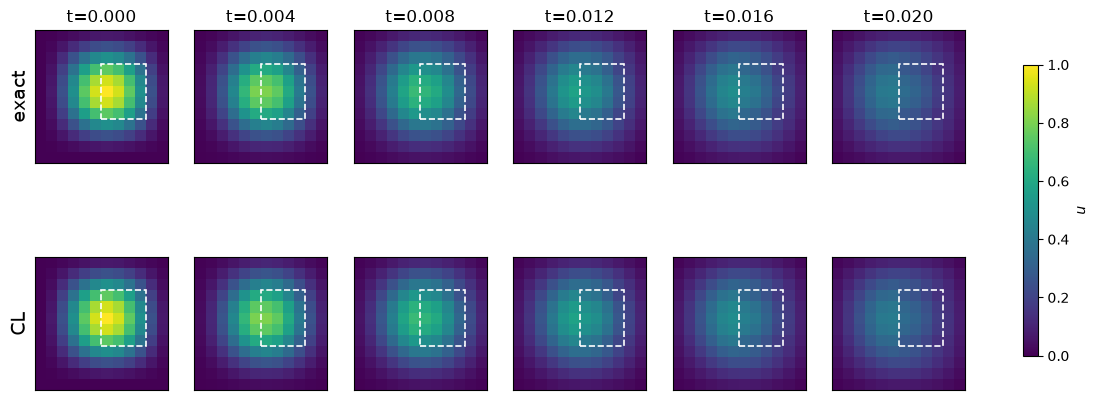

In [9]:
(row_lo, row_hi), (col_lo, col_hi) = box
fig, axes = plt.subplots(2, 6, figsize=(15, 5.4))
for col, t in enumerate(times):
    for row, (data, label) in enumerate(((exact, "exact"), (cl, "CL"))):
        ax = axes[row, col]
        im = ax.imshow(data[col], origin="lower", vmin=0, vmax=1, cmap="viridis")
        ax.add_patch(Rectangle((col_lo - 0.5, row_lo - 0.5), col_hi - col_lo + 1, row_hi - row_lo + 1,
                               fill=False, ec="white", lw=1.2, ls="--"))
        ax.set_xticks([])
        ax.set_yticks([])
        if row == 0:
            ax.set_title(f"t={t:.3f}", fontsize=12)
        if col == 0:
            ax.set_ylabel(label, fontsize=14)
fig.colorbar(im, ax=axes, label=r"$u$", shrink=0.7)
plt.show()

## A position-dependent observable, with `lin_ode.vector`

Reading $u_{a,b}$ back was a plain array index, because a site *is* a basis element.

An observable that is not a basis element needs its expansion coefficients, and `Vector` computes
them: for $g(u)=\sum_{\boldsymbol\alpha}c_{\boldsymbol\alpha}u^{\boldsymbol\alpha}$ it returns
$c_{\boldsymbol\alpha}$ on the same structured index, so

$$g\bigl(u(t)\bigr)=\sum_{\boldsymbol\alpha}c_{\boldsymbol\alpha}\,\boldsymbol\Phi_{\boldsymbol\alpha}(t)$$

is one dot product per frame against the trajectory already solved for, so there is no second
solve.

Take the reaction rate along the grid line $a=6$, which runs through the inclusion at $b=6\dots9$:

$$P(t)=\sum_{b} R(6,b)\,u_{6,b}(t)^2 ,$$

quadratic, so not a basis element, and position-dependent through $R$.

Its coefficient vector *is* $R$ read along that line, so printing it shows the inclusion directly:
$R_0$ up to $b=5$, $R_1$ across $b=6\dots9$, $R_0$ again after.

*(A whole-grid version is the same three lines with the sum over $a$ as well, but costs about
$100\times$ more: `Vector` walks every dof for every term, so the work is #terms $\times$ #lookups
$\times$ #dofs.)*

In [10]:
line = 6  # a grid row that runs through the inclusion
rate = Vector(sum(float(Rg[line, b]) * u[line, b] ** 2 for b in range(n)), basis, u)

support = [(((line, b), 2),) for b in range(n)]  # only these squares can carry weight
cols = [basis.flat_index_of_structured_index(idx) for idx in support]
weights = np.array([float(rate[idx]) for idx in support])

print(f"{'b':>16s} ", "".join(f"{b:6d}" for b in range(n)))
print(f"{f'c[u_({line},b)^2]':>16s} ", "".join(f"{w:6.0f}" for w in weights))

               b       0     1     2     3     4     5     6     7     8     9    10    11
    c[u_(6,b)^2]      -1    -1    -1    -1    -1    -1    -2    -2    -2    -2    -1    -1


**The two curves.** $P$ from the CL trajectory against $P$ evaluated on the direct nonlinear solve.

$P$ is quadratic in the field, so it is the sharper test. The degree-2 block carries $P$ entirely,
and at $K=2$ the truncation cuts that same block.

| read-out | agreement |
|---|---|
| degree-1 profile | $2\cdot10^{-4}$ |
| $P$, degree 2 | $7\cdot10^{-2}$, which is $1\%$ of $P(0)$ and $5\%$ of the smaller $P(T)$ |

P(0) = -7.1830   P(T) = -1.2742   max|CL - exact| = 6.69e-02


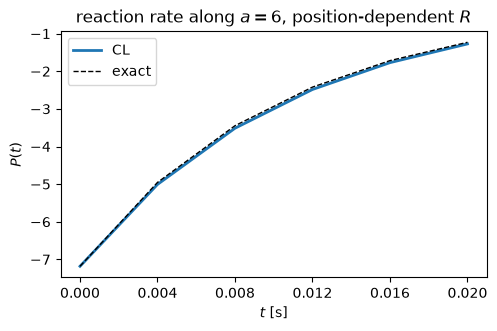

In [11]:
P_cl = traj[:, cols] @ weights  # one dot product per frame; traj is reused, not recomputed
P_exact = (Rg[line] * exact[:, line, :] ** 2).sum(axis=1)
print(f"P(0) = {P_cl[0]:.4f}   P(T) = {P_cl[-1]:.4f}   max|CL - exact| = {np.abs(P_cl - P_exact).max():.2e}")

fig, ax = plt.subplots(figsize=(5.5, 3.2))
ax.plot(times, P_cl, lw=2, label="CL")
ax.plot(times, P_exact, "k--", lw=1, label="exact")
ax.set(xlabel="$t$ [s]", ylabel="$P(t)$", title=f"reaction rate along $a={line}$, position-dependent $R$")
ax.set_xticks(times)  # the 6 solved frames, so the labels do not collide
ax.legend()
plt.show()

---

[← Position-dependent, 1-D](kpp_fisher_position_dependent_1d.ipynb) · [Notebook index](../README.md) · [Pivot switching: KPP–Fisher →](psc_fig3_kpp_fisher.ipynb)